**BÀI TẬP VỀ NHÀ**

BÀI 1

--- Mức nhiễu (Noise) = 50 ---
R2 Score: 0.9994
MSE: 1668.63

--- Mức nhiễu (Noise) = 150 ---
R2 Score: 0.9928
MSE: 19851.81

--- Mức nhiễu (Noise) = 400 ---
R2 Score: 0.9488
MSE: 150463.56



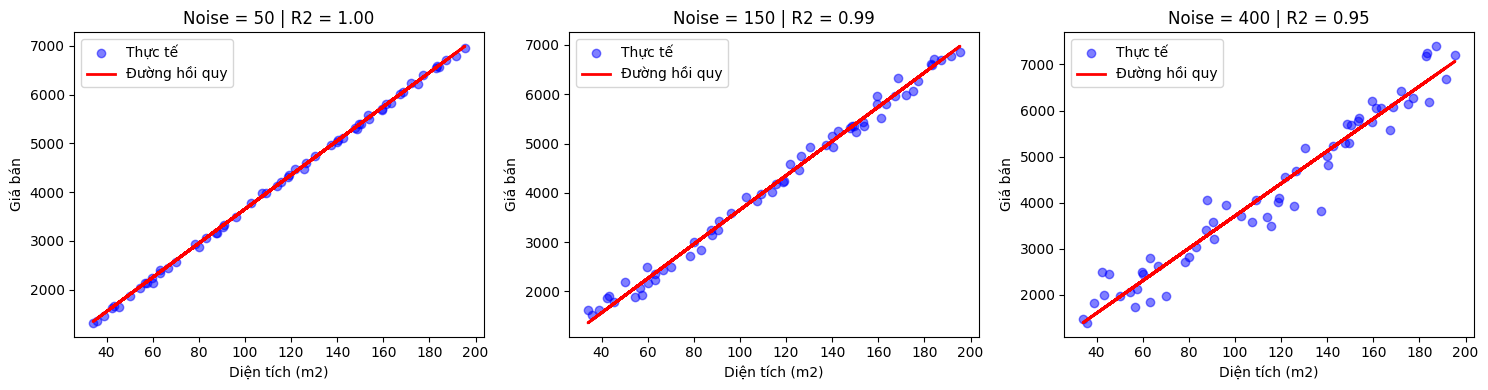

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

np.random.seed(42)
n_samples = 300
X = np.random.uniform(30, 200, (n_samples, 1))

# Thử nghiệm với các mức độ nhiễu (noise) khác nhau
noise_levels = [50, 150, 400]

plt.figure(figsize=(15, 4))

for i, noise in enumerate(noise_levels, 1):
    # Tạo biến mục tiêu y với độ nhiễu tương ứng
    y = 35 * X.flatten() + 150 + np.random.normal(0, noise, n_samples)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)

    print(f"--- Mức nhiễu (Noise) = {noise} ---")
    print(f"R2 Score: {r2:.4f}")
    print(f"MSE: {mse:.2f}\n")

    plt.subplot(1, 3, i)
    plt.scatter(X_test, y_test, color='blue', alpha=0.5, label='Thực tế')
    plt.plot(X_test, y_pred, color='red', linewidth=2, label='Đường hồi quy')
    plt.title(f"Noise = {noise} | R2 = {r2:.2f}")
    plt.xlabel("Diện tích (m2)")
    plt.ylabel("Giá bán")
    plt.legend()

plt.tight_layout()
plt.show()

BÀI 2

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report

# Sinh dữ liệu giả lập
np.random.seed(42)
bmi = np.random.uniform(15, 40, 300).reshape(-1, 1)
z = 0.4 * (bmi - 25)
prob = 1 / (1 + np.exp(-z))
mac_benh = (np.random.rand(300, 1) < prob).astype(int).ravel()

X_train, X_test, y_train, y_test = train_test_split(bmi, mac_benh, test_size=0.2, random_state=42)

#  Huấn luyện mô hình
model = LogisticRegression()
model.fit(X_train, y_train)

#  Lấy xác suất dự đoán cho lớp 1
y_probs = model.predict_proba(X_test)[:, 1]

#  Thử nghiệm thay đổi ngưỡng (Thresholds)
thresholds = [0.3, 0.5, 0.6, 0.7]

for threshold in thresholds:
    # Dự đoán nhãn dựa trên ngưỡng custom
    y_pred_custom = (y_probs >= threshold).astype(int)


    print(f"NGƯỠNG DỰ ĐOÁN (THRESHOLD) = {threshold}")

    print("Ma trận nhầm lẫn (Confusion Matrix):")
    print(confusion_matrix(y_test, y_pred_custom))
    print("\nBáo cáo phân loại:")
    print(classification_report(y_test, y_pred_custom, zero_division=0))

NGƯỠNG DỰ ĐOÁN (THRESHOLD) = 0.3
Ma trận nhầm lẫn (Confusion Matrix):
[[17  7]
 [ 2 34]]

Báo cáo phân loại:
              precision    recall  f1-score   support

           0       0.89      0.71      0.79        24
           1       0.83      0.94      0.88        36

    accuracy                           0.85        60
   macro avg       0.86      0.83      0.84        60
weighted avg       0.86      0.85      0.85        60

NGƯỠNG DỰ ĐOÁN (THRESHOLD) = 0.5
Ma trận nhầm lẫn (Confusion Matrix):
[[21  3]
 [ 3 33]]

Báo cáo phân loại:
              precision    recall  f1-score   support

           0       0.88      0.88      0.88        24
           1       0.92      0.92      0.92        36

    accuracy                           0.90        60
   macro avg       0.90      0.90      0.90        60
weighted avg       0.90      0.90      0.90        60

NGƯỠNG DỰ ĐOÁN (THRESHOLD) = 0.6
Ma trận nhầm lẫn (Confusion Matrix):
[[22  2]
 [ 4 32]]

Báo cáo phân loại:
              preci

BÀI 3

In [3]:
import pandas as pd
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

#  Tải tập dữ liệu nhà ở
housing = fetch_california_housing(as_frame=True)
X = housing.data
y = housing.target

print("Danh sách các thuộc tính (Features):")
print(X.columns.tolist())
print("\n5 dòng đầu tiên của dữ liệu:")
print(X.head())

# Phân chia dữ liệu thành tập huấn luyện (80%) và tập kiểm tra (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Huấn luyện mô hình Linear Regression
model_housing = LinearRegression()
model_housing.fit(X_train, y_train)

# Dự đoán trên tập kiểm tra
y_pred = model_housing.predict(X_test)

# Tính toán các chỉ số đánh giá: MSE và R2 Score
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)


print(" KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH DỰ ĐOÁN GIÁ NHÀ ")

print(f"MSE (Mean Squared Error) : {mse:.4f}")
print(f"R2 Score                 : {r2:.4f}")

# Hiển thị trọng số các thuộc tính tác động đến giá nhà
coef_df = pd.DataFrame({'Thuộc tính': X.columns, 'Hệ số (Weight)': model_housing.coef_})
print("\nTác động của từng thuộc tính lên giá nhà:")
print(coef_df.sort_values(by='Hệ số (Weight)', ascending=False))

Danh sách các thuộc tính (Features):
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

5 dòng đầu tiên của dữ liệu:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  
 KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH DỰ ĐOÁN GIÁ NHÀ 
MSE (Mean Squared Error) : 0.5559
R2 Score                 : 0.5758

Tác động của từng thuộc tính lên giá nhà:
   Thuộc tính  Hệ số (Weight)
3   AveBedrms        0.783145
0      MedInc        0.448675
1    HouseAge        0.009724
4  Population